#Project 13 : CNN Architecture Comparison

1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

np.random.seed(42)
tf.random.set_seed(42)

# Load CIFAR-10
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

y_train = y_train.flatten()
y_test = y_test.flatten()

# Select a subset from each class
train_per_class = 1000
test_per_class = 200

train_indices = np.concatenate([
    np.where(y_train == c)[0][:train_per_class]
    for c in range(10)
])

test_indices = np.concatenate([
    np.where(y_test == c)[0][:test_per_class]
    for c in range(10)
])

X_train = X_train[train_indices]
y_train = y_train[train_indices]

X_test = X_test[test_indices]
y_test = y_test[test_indices]

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Classes:", len(class_names))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2753s 16us/step
Training images: (10000, 32, 32, 3)
Testing images: (2000, 32, 32, 3)
Classes: 10


2. Visualize Image

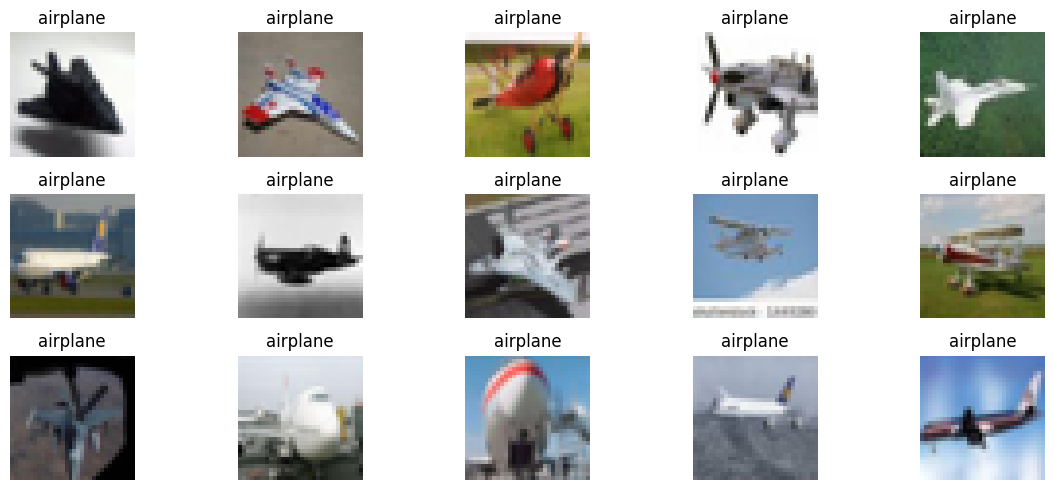

In [2]:
plt.figure(figsize=(12, 5))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

3. Preprocessing the data

In [3]:
X_train_cnn = X_train.astype("float32") / 255.0
X_test_cnn = X_test.astype("float32") / 255.0


X_train_cnn_fit = X_train_cnn[5000:]
y_train_fit = y_train[5000:]

X_val_cnn = X_train_cnn[:5000]
y_val = y_train[:5000]

print("Training samples:", len(y_train_fit))
print("Validation samples:", len(y_val))
print("Testing samples:", len(y_test))

Training samples: 5000
Validation samples: 5000
Testing samples: 2000


4. Building The Custom CNN :

In [4]:
custom_cnn = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

custom_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

5. Training the CNN

In [5]:
start = time.time()

history_cnn = custom_cnn.fit(
    X_train_cnn_fit,
    y_train_fit,
    validation_data=(X_val_cnn, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

time_cnn = time.time() - start

print(f"Custom CNN training time: {time_cnn / 60:.2f} minutes")

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 16s 347ms/step - accuracy: 0.3372 - loss: 1.5809 - val_accuracy: 0.0000e+00 - val_loss: 6.2229
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 20s 334ms/step - accuracy: 0.5126 - loss: 1.2179 - val_accuracy: 0.0000e+00 - val_loss: 7.1565
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 330ms/step - accuracy: 0.5928 - loss: 1.0477 - val_accuracy: 0.0000e+00 - val_loss: 8.4286
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 338ms/step - accuracy: 0.6370 - loss: 0.9602 - val_accuracy: 0.0000e+00 - val_loss: 8.8785
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 20s 309ms/step - accuracy: 0.6816 - loss: 0.8587 - val_accuracy: 0.0000e+00 - val_loss: 9.4003
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 326ms/step - accuracy: 0.7108 - loss: 0.7748 - val_accuracy: 0.0000e+00 - val_loss: 9.6270
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 327ms/step - accuracy: 0.7384 - loss: 0.7127 - val_accuracy: 0.0000e+00 - val_loss: 10.9986
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 21s 339ms/step - accuracy: 0.7

6. Building ResNet50

In [6]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

resnet_model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.Lambda(
        lambda x: preprocess_input(
            tf.cast(x, tf.float32)
        )
    ),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,274 (90.99 MB)

 Trainable params: 263,562 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

7. Resize images and train ResNet50

In [7]:
def prepare_resnet_image(image, label):
    image = tf.image.resize(
        tf.cast(image, tf.float32),
        (96, 96)
    )
    return image, label

BATCH_SIZE = 64

train_resnet_ds = (
    tf.data.Dataset.from_tensor_slices(
        (X_train[5000:], y_train_fit)
    )
    .shuffle(10000, seed=42)
    .map(prepare_resnet_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_resnet_ds = (
    tf.data.Dataset.from_tensor_slices((X_train[:5000], y_val))
    .map(prepare_resnet_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

start = time.time()

history_resnet = resnet_model.fit(
    train_resnet_ds,
    validation_data=val_resnet_ds,
    epochs=5,
    verbose=1
)

time_resnet = time.time() - start

print(f"ResNet50 training time: {time_resnet / 60:.2f} minutes")

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 365s 5s/step - accuracy: 0.8638 - loss: 0.4668 - val_accuracy: 0.0000e+00 - val_loss: 10.0438
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 355s 5s/step - accuracy: 0.9456 - loss: 0.1655 - val_accuracy: 0.0000e+00 - val_loss: 10.4883
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 356s 5s/step - accuracy: 0.9566 - loss: 0.1257 - val_accuracy: 0.0000e+00 - val_loss: 12.9072
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 356s 5s/step - accuracy: 0.9712 - loss: 0.0869 - val_accuracy: 0.0000e+00 - val_loss: 13.0423
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 353s 4s/step - accuracy: 0.9762 - loss: 0.0672 - val_accuracy: 0.0000e+00 - val_loss: 13.7134
ResNet50 training time: 29.74 minutes


8. Training both models

In [8]:
# Custom CNN predictions
prob_cnn = custom_cnn.predict(X_test_cnn, batch_size=128, verbose=0)
pred_cnn = np.argmax(prob_cnn, axis=1)

# ResNet50 test dataset
test_resnet_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(prepare_resnet_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

prob_resnet = resnet_model.predict(test_resnet_ds, verbose=0)
pred_resnet = np.argmax(prob_resnet, axis=1)

acc_cnn = accuracy_score(y_test, pred_cnn)
acc_resnet = accuracy_score(y_test, pred_resnet)

print(f"Custom CNN Test Accuracy: {acc_cnn * 100:.2f}%")
print(f"ResNet50 Test Accuracy: {acc_resnet * 100:.2f}%")

Custom CNN Test Accuracy: 39.00%
ResNet50 Test Accuracy: 47.60%


9. Compare Model Complexity

In [9]:
comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy (%)",
        "Trainable Parameters",
        "Total Parameters",
        "Training Time (minutes)"
    ],
    "Custom CNN": [
        round(acc_cnn * 100, 2),
        sum(np.prod(w.shape) for w in custom_cnn.trainable_weights),
        custom_cnn.count_params(),
        round(time_cnn / 60, 2)
    ],
    "ResNet50": [
        round(acc_resnet * 100, 2),
        sum(np.prod(w.shape) for w in resnet_model.trainable_weights),
        resnet_model.count_params(),
        round(time_resnet / 60, 2)
    ]
})

print(comparison.to_string(index=False))

                 Metric  Custom CNN    ResNet50
      Test Accuracy (%)       39.00       47.60
   Trainable Parameters   356810.00   263562.00
       Total Parameters   356810.00 23851274.00
Training Time (minutes)        2.74       29.74


10. Plotting Accuracy and Training

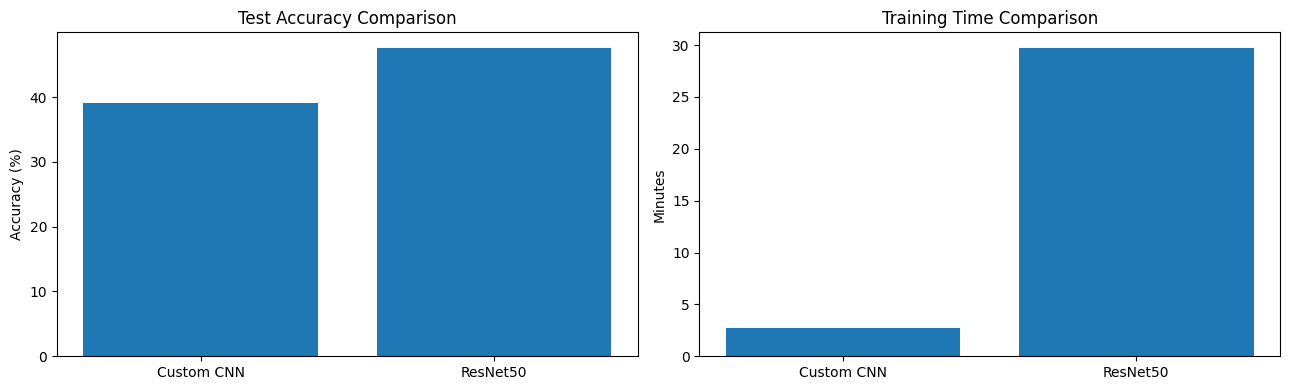

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    ["Custom CNN", "ResNet50"],
    [acc_cnn * 100, acc_resnet * 100]
)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")

axes[1].bar(
    ["Custom CNN", "ResNet50"],
    [time_cnn / 60, time_resnet / 60]
)
axes[1].set_title("Training Time Comparison")
axes[1].set_ylabel("Minutes")

plt.tight_layout()
plt.show()

11. Plot Confusion Matrices

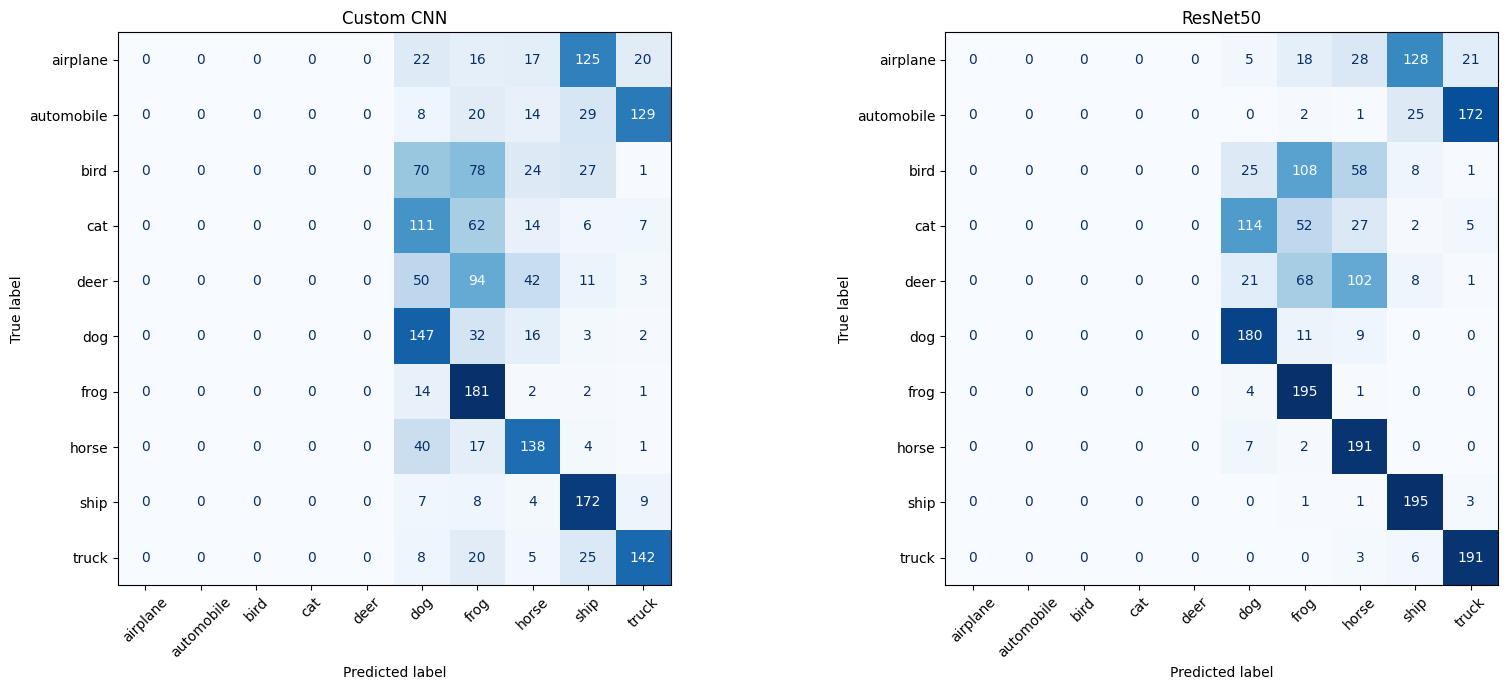

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, predictions, title in [
    (axes[0], pred_cnn, "Custom CNN"),
    (axes[1], pred_resnet, "ResNet50")
]:
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

12. ClassificaTion ReporTs

In [12]:
print("CUSTOM CNN CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    pred_cnn,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nRESNET50 CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    pred_resnet,
    target_names=class_names,
    digits=4,
    zero_division=0
))

CUSTOM CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane     0.0000    0.0000    0.0000       200
  automobile     0.0000    0.0000    0.0000       200
        bird     0.0000    0.0000    0.0000       200
         cat     0.0000    0.0000    0.0000       200
        deer     0.0000    0.0000    0.0000       200
         dog     0.3082    0.7350    0.4343       200
        frog     0.3428    0.9050    0.4973       200
       horse     0.5000    0.6900    0.5798       200
        ship     0.4257    0.8600    0.5695       200
       truck     0.4508    0.7100    0.5515       200

    accuracy                         0.3900      2000
   macro avg     0.2028    0.3900    0.2632      2000
weighted avg     0.2028    0.3900    0.2632      2000


RESNET50 CLASSIFICATION REPORT
              precision    recall  f1-score   support

    airplane     0.0000    0.0000    0.0000       200
  automobile     0.0000    0.0000    0.0000       200
        bird 

13. PredicTions

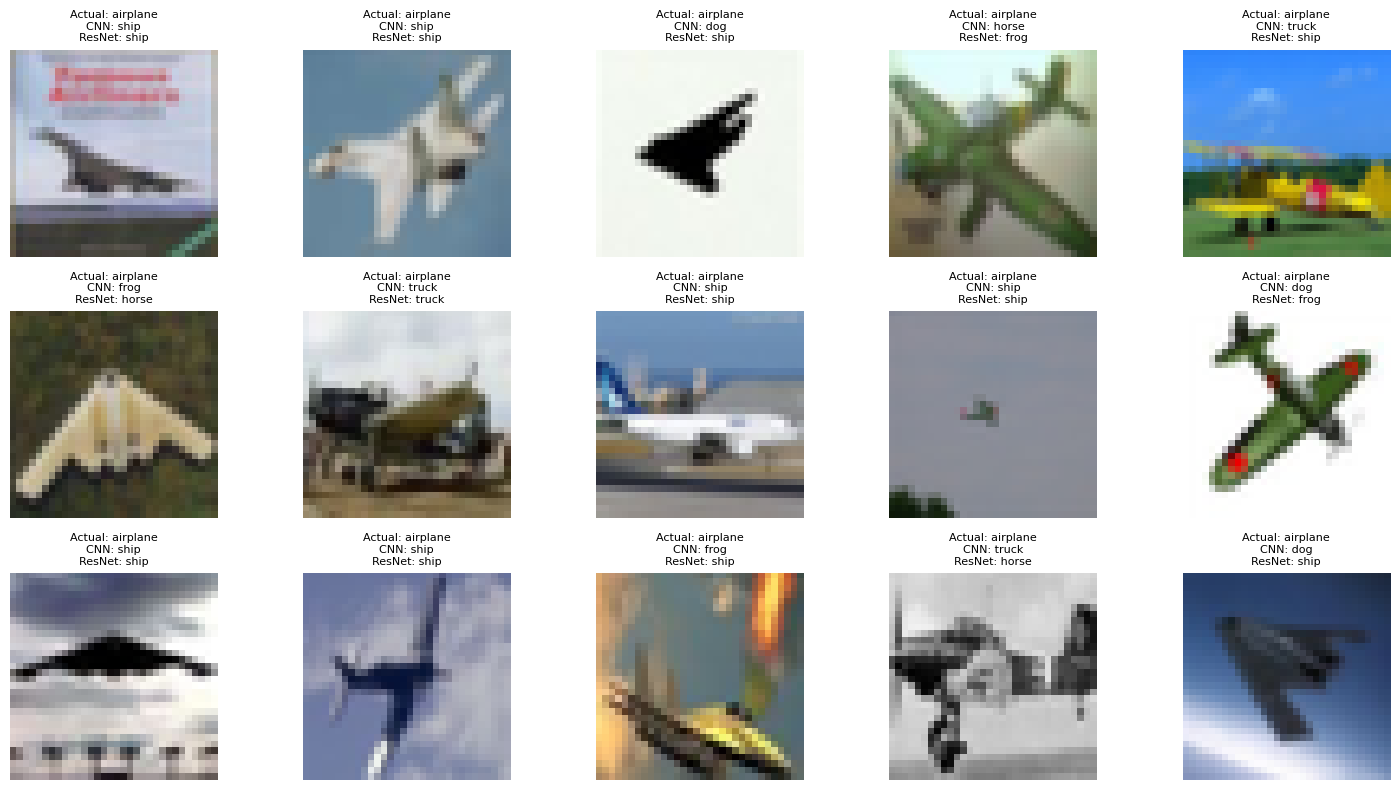

In [13]:
plt.figure(figsize=(15, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i])

    actual = class_names[y_test[i]]
    cnn_prediction = class_names[pred_cnn[i]]
    resnet_prediction = class_names[pred_resnet[i]]

    plt.title(
        f"Actual: {actual}\nCNN: {cnn_prediction}\nResNet: {resnet_prediction}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Conclusion

In this project, two CNN-based image classification models were compared using the CIFAR-10 dataset. The first model was a custom CNN trained from scratch, while the second model used the pretrained ResNet50 architecture with transfer learning.

Both models were evaluated using test accuracy, model complexity, training time, confusion matrices, classification reports, and sample predictions. These metrics helped compare overall performance and identify classes that were frequently misclassified.

The experiment demonstrates that deeper architectures and pretrained features can improve image recognition, although their performance depends on the dataset, training procedure, and computational resources. The custom CNN provides a simpler baseline, while ResNet50 offers a more advanced approach using residual connections and learned ImageNet features.